In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [1]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/deepfake-defense"

folders = [
    "datasets",
    "checkpoints",
    "experiments",
    "reports",
    "models",
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_ROOT, folder), exist_ok=True)

print("Project created at:")
print(PROJECT_ROOT)

print("\nFolders:")
for folder in folders:
    print("✓", folder)

Project created at:
/content/drive/MyDrive/deepfake-defense

Folders:
✓ datasets
✓ checkpoints
✓ experiments
✓ reports
✓ models


In [ ]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/deepfake-defense"

print("Does project folder exist?", os.path.exists(PROJECT_ROOT))

if os.path.exists(PROJECT_ROOT):
    print("\nProject folders:")
    for item in sorted(os.listdir(PROJECT_ROOT)):
        print("✓", item)
else:
    print("\nCreating project folder...")

    folders = [
        "datasets",
        "checkpoints",
        "experiments",
        "reports",
        "models",
    ]

    for folder in folders:
        os.makedirs(os.path.join(PROJECT_ROOT, folder), exist_ok=True)

    print("Created:", PROJECT_ROOT)

Does project folder exist? True

Project folders:
✓ checkpoints
✓ datasets
✓ experiments
✓ models
✓ reports


In [ ]:
!python download-FaceForensics.py -h

usage: download-FaceForensics.py [-h]
                                 [-d {original_youtube_videos,original_youtube_videos_info,original,DeepFakeDetection_original,Deepfakes,DeepFakeDetection,Face2Face,FaceShifter,FaceSwap,NeuralTextures,all}]
                                 [-c {raw,c23,c40}] [-t {videos,masks,models}]
                                 [-n NUM_VIDEOS] [--server {EU,EU2,CA}]
                                 output_path

Downloads FaceForensics v2 public data release.

positional arguments:
  output_path           Output directory.

options:
  -h, --help            show this help message and exit
  -d, --dataset {original_youtube_videos,original_youtube_videos_info,original,DeepFakeDetection_original,Deepfakes,DeepFakeDetection,Face2Face,FaceShifter,FaceSwap,NeuralTextures,all}
                        Which dataset to download, either pristine or
                        manipulated data or the downloaded youtube videos.
                        (default: all)
  -c, --co

In [ ]:
!python download-FaceForensics.py \
    "/content/drive/MyDrive/deepfake-defense/datasets/faceforensics" \
    -d original \
    -c c23 \
    -t videos \
    -n 100 \
    --server EU2


By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use as described at:
http://kaldir.vc.in.tum.de/faceforensics/webpage/FaceForensics_TOS.pdf
***
Press any key to continue, or CTRL-C to exit.

Output path: /content/drive/MyDrive/deepfake-defense/datasets/faceforensics/original_sequences/youtube/c23/videos
100% 100/100 [00:00<00:00, 199.75it/s]


In [ ]:
!python download-FaceForensics.py \
    "/content/drive/MyDrive/deepfake-defense/datasets/faceforensics" \
    -d Deepfakes \
    -c c23 \
    -t videos \
    -n 100 \
    --server EU2

By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use as described at:
http://kaldir.vc.in.tum.de/faceforensics/webpage/FaceForensics_TOS.pdf
***
Press any key to continue, or CTRL-C to exit.

Output path: /content/drive/MyDrive/deepfake-defense/datasets/faceforensics/manipulated_sequences/Deepfakes/c23/videos
100% 100/100 [00:00<00:00, 239.30it/s]


In [ ]:
import os
from pathlib import Path

DATASET_ROOT = Path(
    "/content/drive/MyDrive/deepfake-defense/datasets/faceforensics"
)

real_dir = DATASET_ROOT / "original_sequences" / "youtube" / "c23" / "videos"
fake_dir = DATASET_ROOT / "manipulated_sequences" / "Deepfakes" / "c23" / "videos"

real_videos = sorted(real_dir.glob("*.mp4"))
fake_videos = sorted(fake_dir.glob("*.mp4"))

print("Dataset verification")
print("=" * 40)

print(f"REAL videos : {len(real_videos)}")
print(f"FAKE videos : {len(fake_videos)}")

print("\nREAL example:")
print(real_videos[0] if real_videos else "None")

print("\nFAKE example:")
print(fake_videos[0] if fake_videos else "None")

Dataset verification
REAL videos : 100
FAKE videos : 100

REAL example:
/content/drive/MyDrive/deepfake-defense/datasets/faceforensics/original_sequences/youtube/c23/videos/033.mp4

FAKE example:
/content/drive/MyDrive/deepfake-defense/datasets/faceforensics/manipulated_sequences/Deepfakes/c23/videos/033_097.mp4


In [ ]:
from pathlib import Path

DATASET_ROOT = Path(
    "/content/drive/MyDrive/deepfake-defense/datasets/faceforensics"
)

real_dir = DATASET_ROOT / "original_sequences" / "youtube" / "c23" / "videos"
fake_dir = DATASET_ROOT / "manipulated_sequences" / "Deepfakes" / "c23" / "videos"

real_videos = sorted(real_dir.glob("*.mp4"))
fake_videos = sorted(fake_dir.glob("*.mp4"))

print("REAL videos:", len(real_videos))
print("FAKE videos:", len(fake_videos))

print("\nFirst 10 REAL filenames:")
for x in real_videos[:10]:
    print(x.name)

print("\nFirst 20 FAKE filenames:")
for x in fake_videos[:20]:
    print(x.name)

REAL videos: 100
FAKE videos: 100

First 10 REAL filenames:
033.mp4
035.mp4
036.mp4
044.mp4
046.mp4
055.mp4
062.mp4
066.mp4
097.mp4
107.mp4

First 20 FAKE filenames:
033_097.mp4
035_036.mp4
036_035.mp4
044_945.mp4
046_904.mp4
055_147.mp4
062_066.mp4
066_062.mp4
097_033.mp4
107_109.mp4
109_107.mp4
128_896.mp4
134_192.mp4
147_055.mp4
150_153.mp4
153_150.mp4
159_175.mp4
168_222.mp4
175_159.mp4
183_253.mp4


In [ ]:
import cv2
from pathlib import Path

DATASET_ROOT = Path(
    "/content/drive/MyDrive/deepfake-defense/datasets/faceforensics"
)

real_dir = (
    DATASET_ROOT
    / "original_sequences"
    / "youtube"
    / "c23"
    / "videos"
)

fake_dir = (
    DATASET_ROOT
    / "manipulated_sequences"
    / "Deepfakes"
    / "c23"
    / "videos"
)

test_video = sorted(real_dir.glob("*.mp4"))[0]

cap = cv2.VideoCapture(str(test_video))

print("Testing:", test_video.name)
print("Video opened:", cap.isOpened())
print("Frame count:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print(
    "Resolution:",
    int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
    "x",
    int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
)

cap.release()

Testing: 033.mp4
Video opened: True
Frame count: 809
FPS: 25.0
Resolution: 854 x 480


In [ ]:
!pip install retina-face -q

In [ ]:
from retinaface import RetinaFace

print("RetinaFace imported successfully!")

RetinaFace imported successfully!


In [ ]:
import cv2
from retinaface import RetinaFace

video_path = str(test_video)

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, 400)

success, frame = cap.read()
cap.release()

print("Frame read:", success)
print("Frame shape:", frame.shape if success else None)

# RetinaFace expects an image
detections = RetinaFace.detect_faces(frame)

print("\nDetection result:")
print(detections)

Frame read: True
Frame shape: (480, 854, 3)
26-09-24 06:40:35 - Directory /root/.deepface created
26-09-24 06:40:35 - Directory /root/.deepface/weights created
26-09-24 06:40:35 - retinaface.h5 will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
To: /root/.deepface/weights/retinaface.h5
100%|██████████| 119M/119M [00:01<00:00, 89.3MB/s]



Detection result:
{'face_1': {'score': np.float64(0.9992341995239258), 'facial_area': [np.int64(380), np.int64(50), np.int64(444), np.int64(141)], 'landmarks': {'right_eye': [np.float32(401.77777), np.float32(87.04002)], 'left_eye': [np.float32(431.1908), np.float32(91.90272)], 'nose': [np.float32(415.82462), np.float32(106.149315)], 'mouth_right': [np.float32(400.92932), np.float32(120.01198)], 'mouth_left': [np.float32(422.1105), np.float32(124.06609)]}}, 'face_2': {'score': np.float64(0.9985429048538208), 'facial_area': [np.int64(106), np.int64(222), np.int64(138), np.int64(269)], 'landmarks': {'right_eye': [np.float32(119.8562), np.float32(237.01213)], 'left_eye': [np.float32(134.04262), np.float32(239.23344)], 'nose': [np.float32(128.8323), np.float32(247.6827)], 'mouth_right': [np.float32(119.75276), np.float32(256.99066)], 'mouth_left': [np.float32(129.95033), np.float32(258.89447)]}}, 'face_3': {'score': np.float64(0.9958972930908203), 'facial_area': [np.int64(634), np.int64(1

In [ ]:
import cv2
import numpy as np
from pathlib import Path
from retinaface import RetinaFace
from PIL import Image
import matplotlib.pyplot as plt

# --------------------------------------------------
# Paths
# --------------------------------------------------

DATASET_ROOT = Path(
    "/content/drive/MyDrive/deepfake-defense/datasets/faceforensics"
)

REAL_DIR = (
    DATASET_ROOT
    / "original_sequences"
    / "youtube"
    / "c23"
    / "videos"
)

FAKE_DIR = (
    DATASET_ROOT
    / "manipulated_sequences"
    / "Deepfakes"
    / "c23"
    / "videos"
)

OUTPUT_ROOT = (
    "/content/drive/MyDrive/deepfake-defense/datasets/processed_test"
)

Path(OUTPUT_ROOT, "real").mkdir(parents=True, exist_ok=True)
Path(OUTPUT_ROOT, "fake").mkdir(parents=True, exist_ok=True)


# --------------------------------------------------
# Face selection
# --------------------------------------------------

def select_primary_face(detections, min_size=40):

    candidates = []

    for face_id, data in detections.items():

        score = float(data["score"])

        x1, y1, x2, y2 = map(
            int,
            data["facial_area"]
        )

        width = x2 - x1
        height = y2 - y1

        if width >= min_size and height >= min_size:

            area = width * height

            candidates.append(
                {
                    "face_id": face_id,
                    "score": score,
                    "area": area,
                    "box": (x1, y1, x2, y2),
                    "landmarks": data["landmarks"]
                }
            )

    if not candidates:
        return None

    # Prefer large, high-confidence faces.
    candidates.sort(
        key=lambda x: (x["area"], x["score"]),
        reverse=True
    )

    return candidates[0]


# --------------------------------------------------
# Extract frames from one video
# --------------------------------------------------

def extract_test_frames(
    video_path,
    output_dir,
    label,
    num_frames=10
):

    cap = cv2.VideoCapture(str(video_path))

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num_frames,
        dtype=int
    )

    saved = 0

    for frame_number in frame_indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_number)
        )

        success, frame = cap.read()

        if not success:
            continue

        # BGR → RGB
        rgb_frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        # RetinaFace detection
        detections = RetinaFace.detect_faces(
            rgb_frame
        )

        if not isinstance(detections, dict):
            continue

        face = select_primary_face(
            detections
        )

        if face is None:
            continue

        x1, y1, x2, y2 = face["box"]

        # Add a small margin around face
        margin = 20

        h, w = rgb_frame.shape[:2]

        x1 = max(0, x1 - margin)
        y1 = max(0, y1 - margin)
        x2 = min(w, x2 + margin)
        y2 = min(h, y2 + margin)

        face_crop = rgb_frame[
            y1:y2,
            x1:x2
        ]

        if face_crop.size == 0:
            continue

        # Resize
        face_crop = cv2.resize(
            face_crop,
            (224, 224),
            interpolation=cv2.INTER_AREA
        )

        filename = (
            f"{Path(video_path).stem}"
            f"_frame_{frame_number:05d}.jpg"
        )

        output_path = (
            Path(output_dir) / filename
        )

        Image.fromarray(face_crop).save(
            output_path,
            quality=95
        )

        saved += 1

    cap.release()

    print(
        f"{label}: {Path(video_path).name} "
        f"→ {saved}/{num_frames} faces saved"
    )


# --------------------------------------------------
# Test on one REAL + one FAKE
# --------------------------------------------------

real_video = sorted(
    REAL_DIR.glob("*.mp4")
)[0]

fake_video = sorted(
    FAKE_DIR.glob("*.mp4")
)[0]

extract_test_frames(
    real_video,
    Path(OUTPUT_ROOT, "real"),
    "REAL"
)

extract_test_frames(
    fake_video,
    Path(OUTPUT_ROOT, "fake"),
    "FAKE"
)

REAL: 033.mp4 → 10/10 faces saved
FAKE: 033_097.mp4 → 10/10 faces saved


REAL crops: 10
FAKE crops: 10


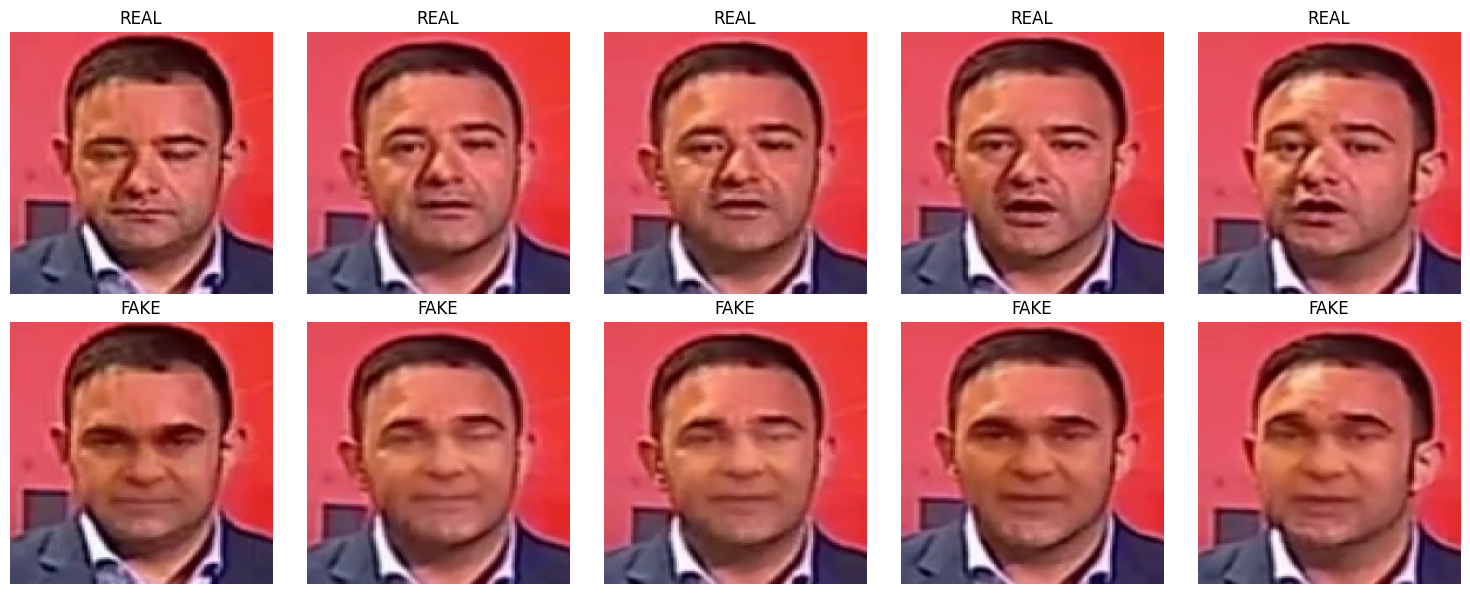

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

OUTPUT_ROOT = Path(
    "/content/drive/MyDrive/deepfake-defense/datasets/processed_test"
)

real_images = sorted((OUTPUT_ROOT / "real").glob("*.jpg"))
fake_images = sorted((OUTPUT_ROOT / "fake").glob("*.jpg"))

print("REAL crops:", len(real_images))
print("FAKE crops:", len(fake_images))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, img_path in zip(axes[0], real_images[:5]):
    ax.imshow(Image.open(img_path))
    ax.set_title("REAL")
    ax.axis("off")

for ax, img_path in zip(axes[1], fake_images[:5]):
    ax.imshow(Image.open(img_path))
    ax.set_title("FAKE")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import cv2
import numpy as np
from pathlib import Path
from retinaface import RetinaFace
from PIL import Image
import pandas as pd
from tqdm.auto import tqdm

# =========================
# PATHS
# =========================

DATASET_ROOT = Path(
    "/content/drive/MyDrive/deepfake-defense/datasets/faceforensics"
)

REAL_DIR = (
    DATASET_ROOT
    / "original_sequences"
    / "youtube"
    / "c23"
    / "videos"
)

FAKE_DIR = (
    DATASET_ROOT
    / "manipulated_sequences"
    / "Deepfakes"
    / "c23"
    / "videos"
)

OUTPUT_ROOT = Path(
    "/content/drive/MyDrive/deepfake-defense/datasets/processed"
)

REAL_OUT = OUTPUT_ROOT / "real"
FAKE_OUT = OUTPUT_ROOT / "fake"

REAL_OUT.mkdir(parents=True, exist_ok=True)
FAKE_OUT.mkdir(parents=True, exist_ok=True)


# =========================
# FACE SELECTION
# =========================

def select_primary_face(detections, min_size=40):

    candidates = []

    for face_id, data in detections.items():

        score = float(data["score"])

        x1, y1, x2, y2 = map(
            int,
            data["facial_area"]
        )

        width = x2 - x1
        height = y2 - y1

        if width >= min_size and height >= min_size:

            area = width * height

            candidates.append({
                "face_id": face_id,
                "score": score,
                "area": area,
                "box": (x1, y1, x2, y2)
            })

    if not candidates:
        return None

    # Largest face first, confidence as tie-breaker
    candidates.sort(
        key=lambda x: (x["area"], x["score"]),
        reverse=True
    )

    return candidates[0]


# =========================
# PROCESS ONE VIDEO
# =========================

def process_video(
    video_path,
    output_dir,
    label,
    num_frames=10
):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        return 0

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    if total_frames <= 0:
        cap.release()
        return 0

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num_frames,
        dtype=int
    )

    saved = 0

    for frame_number in frame_indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_number)
        )

        success, frame = cap.read()

        if not success:
            continue

        # OpenCV BGR → RGB
        rgb_frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        # RetinaFace detection
        detections = RetinaFace.detect_faces(
            rgb_frame
        )

        if not isinstance(detections, dict):
            continue

        face = select_primary_face(
            detections
        )

        if face is None:
            continue

        x1, y1, x2, y2 = face["box"]

        # Add margin around face
        margin = 20

        h, w = rgb_frame.shape[:2]

        x1 = max(0, x1 - margin)
        y1 = max(0, y1 - margin)
        x2 = min(w, x2 + margin)
        y2 = min(h, y2 + margin)

        face_crop = rgb_frame[
            y1:y2,
            x1:x2
        ]

        if face_crop.size == 0:
            continue

        # Resize for Xception / ViT
        face_crop = cv2.resize(
            face_crop,
            (224, 224),
            interpolation=cv2.INTER_AREA
        )

        filename = (
            f"{video_path.stem}"
            f"_frame_{frame_number:05d}.jpg"
        )

        output_path = output_dir / filename

        Image.fromarray(
            face_crop
        ).save(
            output_path,
            quality=95
        )

        saved += 1

    cap.release()

    return saved


# =========================
# PROCESS ALL VIDEOS
# =========================

real_videos = sorted(
    REAL_DIR.glob("*.mp4")
)

fake_videos = sorted(
    FAKE_DIR.glob("*.mp4")
)

print("REAL videos:", len(real_videos))
print("FAKE videos:", len(fake_videos))


# REAL
real_total = 0

for video in tqdm(
    real_videos,
    desc="Processing REAL videos"
):

    real_total += process_video(
        video,
        REAL_OUT,
        "REAL",
        num_frames=10
    )


# FAKE
fake_total = 0

for video in tqdm(
    fake_videos,
    desc="Processing FAKE videos"
):

    fake_total += process_video(
        video,
        FAKE_OUT,
        "FAKE",
        num_frames=10
    )


print("\n==============================")
print("PREPROCESSING COMPLETE")
print("==============================")
print("REAL face images:", real_total)
print("FAKE face images:", fake_total)
print("Total images:", real_total + fake_total)

REAL videos: 100
FAKE videos: 100


Processing REAL videos:   0%|          | 0/100 [00:00<?, ?it/s]

Processing FAKE videos:   0%|          | 0/100 [00:00<?, ?it/s]


PREPROCESSING COMPLETE
REAL face images: 1000
FAKE face images: 1000
Total images: 2000


In [ ]:
from pathlib import Path

BASE = Path(
    "/content/drive/MyDrive/deepfake-defense/datasets"
)

print("Checking project dataset folders...\n")

for p in BASE.iterdir():
    print(p)

print("\nSearching for extracted JPG images...")

jpg_files = list(BASE.rglob("*.jpg"))

print("Total JPG files found:", len(jpg_files))

for p in jpg_files[:20]:
    print(p)

Checking project dataset folders...

/content/drive/MyDrive/deepfake-defense/datasets/faceforensics
/content/drive/MyDrive/deepfake-defense/datasets/processed_test
/content/drive/MyDrive/deepfake-defense/datasets/processed

Searching for extracted JPG images...
Total JPG files found: 2020
/content/drive/MyDrive/deepfake-defense/datasets/processed/real/033_frame_00000.jpg
/content/drive/MyDrive/deepfake-defense/datasets/processed/real/033_frame_00089.jpg
/content/drive/MyDrive/deepfake-defense/datasets/processed/real/033_frame_00179.jpg
/content/drive/MyDrive/deepfake-defense/datasets/processed/real/033_frame_00359.jpg
/content/drive/MyDrive/deepfake-defense/datasets/processed/real/033_frame_00269.jpg
/content/drive/MyDrive/deepfake-defense/datasets/processed/real/033_frame_00448.jpg
/content/drive/MyDrive/deepfake-defense/datasets/processed/real/033_frame_00538.jpg
/content/drive/MyDrive/deepfake-defense/datasets/processed/real/033_frame_00808.jpg
/content/drive/MyDrive/deepfake-defens

In [ ]:
from pathlib import Path
import pandas as pd

PROCESSED_ROOT = Path(
    "/content/drive/MyDrive/deepfake-defense/datasets/processed"
)

rows = []

# REAL
for img in sorted((PROCESSED_ROOT / "real").glob("*.jpg")):
    video_id = img.name.split("_frame_")[0]

    frame_number = int(
        img.stem.split("_frame_")[1]
    )

    rows.append({
        "image_path": str(img),
        "video_id": video_id,
        "frame_number": frame_number,
        "label": 0,
        "class": "REAL"
    })


# FAKE
for img in sorted((PROCESSED_ROOT / "fake").glob("*.jpg")):
    video_id = img.name.split("_frame_")[0]

    frame_number = int(
        img.stem.split("_frame_")[1]
    )

    rows.append({
        "image_path": str(img),
        "video_id": video_id,
        "frame_number": frame_number,
        "label": 1,
        "class": "FAKE"
    })


manifest = pd.DataFrame(rows)

print("Total images:", len(manifest))
print("Unique videos:", manifest["video_id"].nunique())

print("\nClass distribution:")
print(manifest["class"].value_counts())

print("\nImages per class:")
print(manifest.groupby("class").size())

print("\nFirst 10 rows:")
display(manifest.head(10))


# Save
MANIFEST_PATH = (
    PROCESSED_ROOT / "manifest.csv"
)

manifest.to_csv(
    MANIFEST_PATH,
    index=False
)

print("\nManifest saved:")
print(MANIFEST_PATH)

Total images: 2000
Unique videos: 200

Class distribution:
class
REAL    1000
FAKE    1000
Name: count, dtype: int64

Images per class:
class
FAKE    1000
REAL    1000
dtype: int64

First 10 rows:


,image_path,video_id,frame_number,label,class
0,/content/drive/MyDrive/deepfake-defense/datase...,033,0,0,REAL
1,/content/drive/MyDrive/deepfake-defense/datase...,033,89,0,REAL
2,/content/drive/MyDrive/deepfake-defense/datase...,033,179,0,REAL
3,/content/drive/MyDrive/deepfake-defense/datase...,033,269,0,REAL
4,/content/drive/MyDrive/deepfake-defense/datase...,033,359,0,REAL
5,/content/drive/MyDrive/deepfake-defense/datase...,033,448,0,REAL
6,/content/drive/MyDrive/deepfake-defense/datase...,033,538,0,REAL
7,/content/drive/MyDrive/deepfake-defense/datase...,033,628,0,REAL
8,/content/drive/MyDrive/deepfake-defense/datase...,033,718,0,REAL
9,/content/drive/MyDrive/deepfake-defense/datase...,033,808,0,REAL



Manifest saved:
/content/drive/MyDrive/deepfake-defense/datasets/processed/manifest.csv


In [ ]:
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# Load manifest
MANIFEST_PATH = Path(
    "/content/drive/MyDrive/deepfake-defense/datasets/processed/manifest.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

print("Total images:", len(manifest))
print("Total videos:", manifest["video_id"].nunique())


# --------------------------------------------------
# Get one row per video
# --------------------------------------------------

videos = (
    manifest[["video_id", "label"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("\nVideos by class:")
print(videos["label"].value_counts())


# --------------------------------------------------
# 70% TRAIN / 15% VALIDATION / 15% TEST
# --------------------------------------------------

train_videos, temp_videos = train_test_split(
    videos,
    test_size=0.30,
    stratify=videos["label"],
    random_state=42
)

val_videos, test_videos = train_test_split(
    temp_videos,
    test_size=0.50,
    stratify=temp_videos["label"],
    random_state=42
)


# --------------------------------------------------
# Assign split to each image
# --------------------------------------------------

train_ids = set(train_videos["video_id"])
val_ids = set(val_videos["video_id"])
test_ids = set(test_videos["video_id"])


def assign_split(video_id):
    if video_id in train_ids:
        return "train"
    elif video_id in val_ids:
        return "val"
    elif video_id in test_ids:
        return "test"
    else:
        return None


manifest["split"] = manifest["video_id"].apply(assign_split)


# --------------------------------------------------
# Check split
# --------------------------------------------------

print("\n==============================")
print("VIDEO SPLIT")
print("==============================")

print("\nVideos:")
print(
    "TRAIN:",
    len(train_ids)
)

print(
    "VAL:",
    len(val_ids)
)

print(
    "TEST:",
    len(test_ids)
)

print("\nImages:")
print(
    manifest["split"].value_counts()
)

print("\nClass distribution:")
print(
    pd.crosstab(
        manifest["split"],
        manifest["class"]
    )
)


# --------------------------------------------------
# Check for leakage
# --------------------------------------------------

train_val_overlap = train_ids & val_ids
train_test_overlap = train_ids & test_ids
val_test_overlap = val_ids & test_ids

print("\n==============================")
print("LEAKAGE CHECK")
print("==============================")

print("Train ∩ Val:", len(train_val_overlap))
print("Train ∩ Test:", len(train_test_overlap))
print("Val ∩ Test:", len(val_test_overlap))


# --------------------------------------------------
# Save new manifest
# --------------------------------------------------

SPLIT_MANIFEST = (
    Path(
        "/content/drive/MyDrive/deepfake-defense/datasets/processed"
    )
    / "manifest_with_split.csv"
)

manifest.to_csv(
    SPLIT_MANIFEST,
    index=False
)

print("\nSaved:")
print(SPLIT_MANIFEST)

Total images: 2000
Total videos: 200

Videos by class:
label
0    100
1    100
Name: count, dtype: int64

VIDEO SPLIT

Videos:
TRAIN: 140
VAL: 30
TEST: 30

Images:
split
train    1400
val       300
test      300
Name: count, dtype: int64

Class distribution:
class  FAKE  REAL
split            
test    150   150
train   700   700
val     150   150

LEAKAGE CHECK
Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0

Saved:
/content/drive/MyDrive/deepfake-defense/datasets/processed/manifest_with_split.csv


In [ ]:
import pandas as pd
import torch

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


# ==========================================
# 1. LOAD MANIFEST
# ==========================================

MANIFEST_PATH = Path(
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_with_split.csv"
)

df = pd.read_csv(MANIFEST_PATH)

print("Total images:", len(df))
print(df["split"].value_counts())


# ==========================================
# 2. IMAGE TRANSFORMS
# ==========================================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=5
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ==========================================
# 3. CUSTOM DATASET
# ==========================================

class DeepfakeDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.transform = transform

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image_path = row["image_path"]
        label = int(row["label"])

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(
            label,
            dtype=torch.long
        )


# ==========================================
# 4. SPLIT DATA
# ==========================================

train_df = df[
    df["split"] == "train"
].copy()

val_df = df[
    df["split"] == "val"
].copy()

test_df = df[
    df["split"] == "test"
].copy()


print("\nDataset sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


# ==========================================
# 5. CREATE DATASETS
# ==========================================

train_dataset = DeepfakeDataset(
    train_df,
    transform=train_transform
)

val_dataset = DeepfakeDataset(
    val_df,
    transform=val_test_transform
)

test_dataset = DeepfakeDataset(
    test_df,
    transform=val_test_transform
)


# ==========================================
# 6. CREATE DATALOADERS
# ==========================================

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ==========================================
# 7. CHECK ONE BATCH
# ==========================================

images, labels = next(
    iter(train_loader)
)

print("\nBatch check:")
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Labels:", labels[:10])
print("Device available:", torch.cuda.is_available())

Total images: 2000
split
train    1400
val       300
test      300
Name: count, dtype: int64

Dataset sizes:
Train: 1400
Validation: 300
Test: 300

Batch check:
Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Labels: tensor([0, 1, 1, 1, 1, 1, 1, 0, 1, 0])
Device available: True


In [ ]:
from PIL import Image
from pathlib import Path

processed = Path(
    "/content/drive/MyDrive/deepfake-defense/datasets/processed"
)

sizes = {}

for img_path in list(processed.rglob("*.jpg"))[:100]:
    size = Image.open(img_path).size
    sizes[size] = sizes.get(size, 0) + 1

print("Image sizes:")
for size, count in sizes.items():
    print(size, ":", count)

Image sizes:
(224, 224) : 100


In [2]:
from pathlib import Path

print("Drive dataset exists:",
      Path("/content/drive/MyDrive/deepfake-defense/datasets").exists())

print("Processed images exist:",
      Path("/content/drive/MyDrive/deepfake-defense/datasets/processed").exists())

Drive dataset exists: True
Processed images exist: True


In [3]:

from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/deepfake-defense/datasets")

print("=== PROCESSED DATASET ===")

for folder in [
    root / "processed" / "real",
    root / "processed" / "fake",
]:
    count = (
        sum(1 for p in folder.iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
        if folder.exists() else 0
    )
    print(f"{folder.name}: {count} images")

print("\n=== MANIFEST FILES ===")

for name in [
    "manifest.csv",
    "manifest_with_split.csv",
    "manifest_source_aware.csv",
]:
    path = root / "processed" / name

    if path.exists():
        df = pd.read_csv(path)
        print(f"\n{name}: {len(df)} rows")
        print("Columns:", df.columns.tolist())
    else:
        print(f"{name}: NOT FOUND")


=== PROCESSED DATASET ===
real: 1000 images
fake: 1000 images

=== MANIFEST FILES ===

manifest.csv: 2000 rows
Columns: ['image_path', 'video_id', 'frame_number', 'label', 'class']

manifest_with_split.csv: 2000 rows
Columns: ['image_path', 'video_id', 'frame_number', 'label', 'class', 'split']

manifest_source_aware.csv: 2000 rows
Columns: ['image_path', 'video_id', 'frame_number', 'label', 'class', 'split', 'group_id', 'group_split', 'source_group_id', 'source_aware_split']
